# Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import kpss
import pymannkendall as mk
from scipy.stats import kruskal

from utils.constants import CAMS_VARS, ERA5_VARS, STATES
from utils.dataset_manipulators import create_lags


# Data Visualization

In [2]:
df_consumption = pd.read_csv("../data/processed/dataset.csv")
df_consumption_cleaned = pd.read_csv("../data/processed/dataset_final.csv")
df_consumption["Date"] = pd.to_datetime(df_consumption["Date"], format="%m/%Y")
df_consumption = df_consumption.set_index("Date")

targets = ["Residential", "Industrial", "Commercial", "Other"]
consumers = ["Residential Consumers", "Industrial Consumers", "Commercial Consumers", "Other Consumers"]
weather_features = [col for col in df_consumption.columns if col not in targets + consumers + ["State"]]

scalers = {}

def plot_targets(df, sufix):
    fig, ax = plt.subplots(figsize=(8, 5))
    for target in targets:
        ax.plot(df.index, df[target], label=target)

    ax.set_xlabel("Year", fontsize=14, fontweight='bold')
    ax.set_ylabel("Consumption (MWh)", fontsize=14, fontweight='bold')

    ax.tick_params(axis='both', which='major', labelsize=12)

    ax.ticklabel_format(style="plain", axis="y")
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{x:,.1f}"))

    plt.xticks(rotation=90)

    ax.grid(True, linestyle="--", alpha=0.6)

    plt.legend(fontsize=12)

    plt.tight_layout()
    plt.savefig(f"../paper/materials/consumption{sufix}.png")
    plt.show()

df_consumption.isnull().sum()


State                        0
Month                        0
Year                         0
State_PR                     0
State_RS                     0
                            ..
Total cloud cover_Q3_1800    0
Total cloud cover_Q3_2100    0
Total cloud cover_Q4_0900    0
Total cloud cover_Q4_1800    0
Total cloud cover_Q4_2100    0
Length: 144, dtype: int64

## Paraná

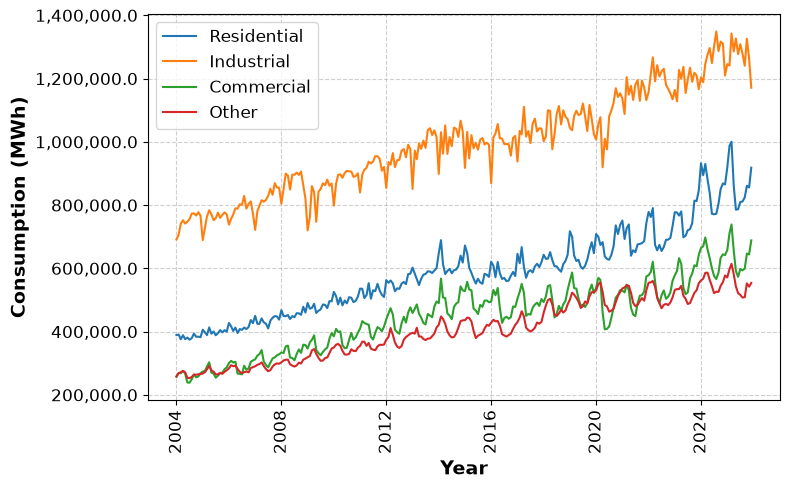

In [3]:
df_pr = df_consumption[df_consumption["State"] == "PR"]
plot_targets(df_pr, "_PR")

## Santa Catarina

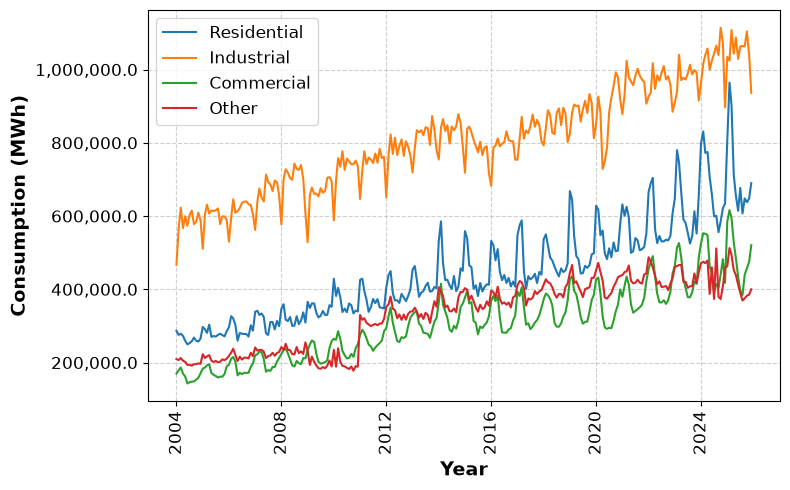

In [4]:
df_sc = df_consumption[df_consumption["State"] == "SC"]
plot_targets(df_sc, "_SC")

## Rio Grande do Sul

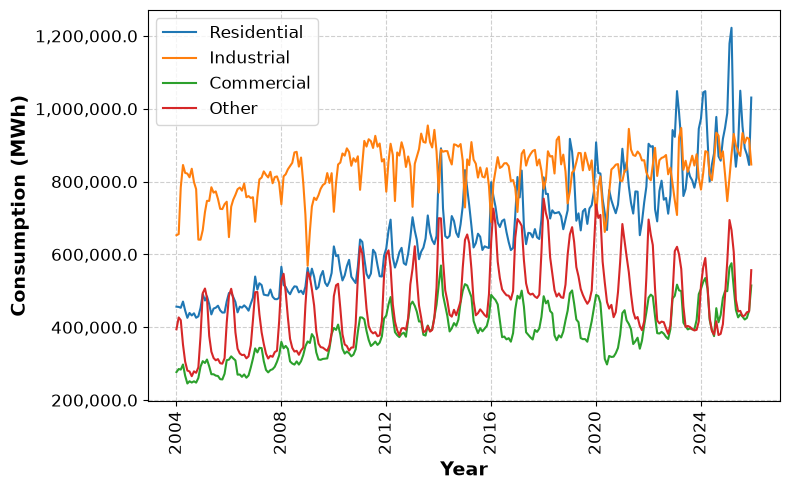

In [5]:
df_rs = df_consumption[df_consumption["State"] == "RS"]
plot_targets(df_rs, "_RS")

# Statistical Summary

In [6]:
def plot_acf_pacf(df_state, state_name, lags=12):
    fig, axes = plt.subplots(nrows=len(targets), ncols=2, figsize=(14, 3 * len(targets)))
    
    for i, target in enumerate(targets):
        serie = df_state[target].dropna()
        
        # ACF
        plot_acf(serie, ax=axes[i, 0], lags=lags, alpha=0.05, title=f"ACF - {target} ({state_name})")
        axes[i, 0].set_xlabel("Lag (Months)", fontsize=11, fontweight="bold")
        axes[i, 0].set_ylabel("ACF", fontsize=11, fontweight="bold")
        axes[i, 0].set_xticks(range(0, lags + 1, 6))
        axes[i, 0].grid(True, linestyle="--", alpha=0.6)
        
        # PACF
        plot_pacf(serie, ax=axes[i, 1], lags=lags, alpha=0.05, method="ywm", title=f"PACF - {target} ({state_name})")
        axes[i, 1].set_xlabel("Lag (Months)", fontsize=11, fontweight="bold")
        axes[i, 1].set_ylabel("PACF", fontsize=11, fontweight="bold")
        axes[i, 1].set_xticks(range(0, lags + 1, 6))
        axes[i, 1].grid(True, linestyle="--", alpha=0.6)
        
    plt.tight_layout()
    plt.savefig(f"../paper/materials/acf_pacf_{state_name}.png", dpi=300, bbox_inches="tight")
    plt.show()

def run_hypothesis_tests(df_state, state_name):
    rows = []
    for target in targets:
        serie = df_state[target].dropna()
        
        # 1. KPSS Test (Stationarity)
        # H0: Series is stationary | H1: Series has unit root (non-stationary)
        kpss_stat, kpss_p = kpss(serie, regression="c", nlags="auto", result_object=True)
        kpss_concl = "Stationary" if kpss_p >= 0.05 else "Non-Stationary"
        kpss_p_str = "<= 0.01" if kpss_p <= 0.01 else (">= 0.10" if kpss_p >= 0.10 else f"{kpss_p:.4f}")
        
        # 2. Mann-Kendall Test (Monotonic Trend)
        # H0: No monotonic trend | H1: Presence of monotonic trend
        mk_res = mk.original_test(serie)
        if mk_res.p < 0.05:
            mk_concl = "Upward Trend" if mk_res.Tau > 0 else "Downward Trend"
        else:
            mk_concl = "No Trend"
        mk_p_str = f"{mk_res.p:.2e}" if mk_res.p < 0.001 else f"{mk_res.p:.4f}"
        
        # 3. Kruskal-Wallis Test (Monthly Seasonality)
        # H0: Medians of 12 months are equal (Non-Seasonal) | H1: At least two months differ (Seasonal)
        monthly_groups = [group.values for _, group in serie.groupby(serie.index.month)]
        kw_stat, kw_p = kruskal(*monthly_groups)
        kw_concl = "Seasonal" if kw_p < 0.05 else "Non-Seasonal"
        kw_p_str = f"{kw_p:.2e}" if kw_p < 0.001 else f"{kw_p:.4f}"
        
        rows.append({
            "State": state_name,
            "Consumption": target,
            "KPSS Stat": np.round(kpss_stat, 4),
            "KPSS p-value": kpss_p_str,
            "KPSS Conclusion (alpha=0.05)": kpss_concl,
            "MK Tau": np.round(mk_res.Tau, 4),
            "MK Sen Slope": np.round(mk_res.slope, 2),
            "MK p-value": mk_p_str,
            "MK Conclusion (alpha=0.05)": mk_concl,
            "KW Stat": np.round(kw_stat, 4),
            "KW p-value": kw_p_str,
            "KW Conclusion (alpha=0.05)": kw_concl
        })
        
    df_res = pd.DataFrame(rows)
    df_res = df_res.set_index(["State", "Consumption"])
    return df_res

resumo_list = []

for state in STATES:
    df_state = df_consumption[df_consumption[f"State"] == state]
    
    for target in targets:
        serie = df_state[target]
        resumo_list.append({
            "State": state,
            "Consumption": target,
            "Frequency": "Monthly",
            "Data Points": int(serie.count()),
            "Mean": np.round(serie.mean(), 2),
            "Standard Deviation": np.round(serie.std(), 2),
            "Min": serie.min(),
            "Max": serie.max(),
        })

df_resumo = pd.DataFrame(resumo_list)
df_resumo = df_resumo.set_index(["State", "Consumption"])
df_resumo.to_csv("../paper/materials/statistical_summary.csv")

display(df_resumo)

Frequency  Data Points       Mean  Standard Deviation  \
State Consumption                                                         
PR    Residential   Monthly          264  588623.02           136901.31   
      Industrial    Monthly          264  994908.85           160640.86   
      Commercial    Monthly          264  449809.03           112118.44   
      Other         Monthly          264  409099.13            96196.48   
SC    Residential   Monthly          264  446916.29           135414.10   
      Industrial    Monthly          264  806137.12           140741.45   
      Commercial    Monthly          264  310229.58            99965.80   
      Other         Monthly          264  334841.82            93412.95   
RS    Residential   Monthly          264  666076.95           158767.30   
      Industrial    Monthly          264  827609.92            65776.92   
      Commercial    Monthly          264  387169.83            72836.84   
      Other         Monthly          264  468573.98           108971.92   

                      Min      Max  
State Consumption                   
PR    Residential  374402  1000354  
      Industrial   689452  1348993  
      Commercial   238401   738650  
      Other        252785   614318  
SC    Residential  249891   964376  
      Industrial   466790  1114040  
      Commercial   142886   616189  
      Other        177855   512640  
RS    Residential  425987  1222330  
      Industrial   568855   954097  
      Commercial   245687   575937  
      Other        265760   753217

## Paraná

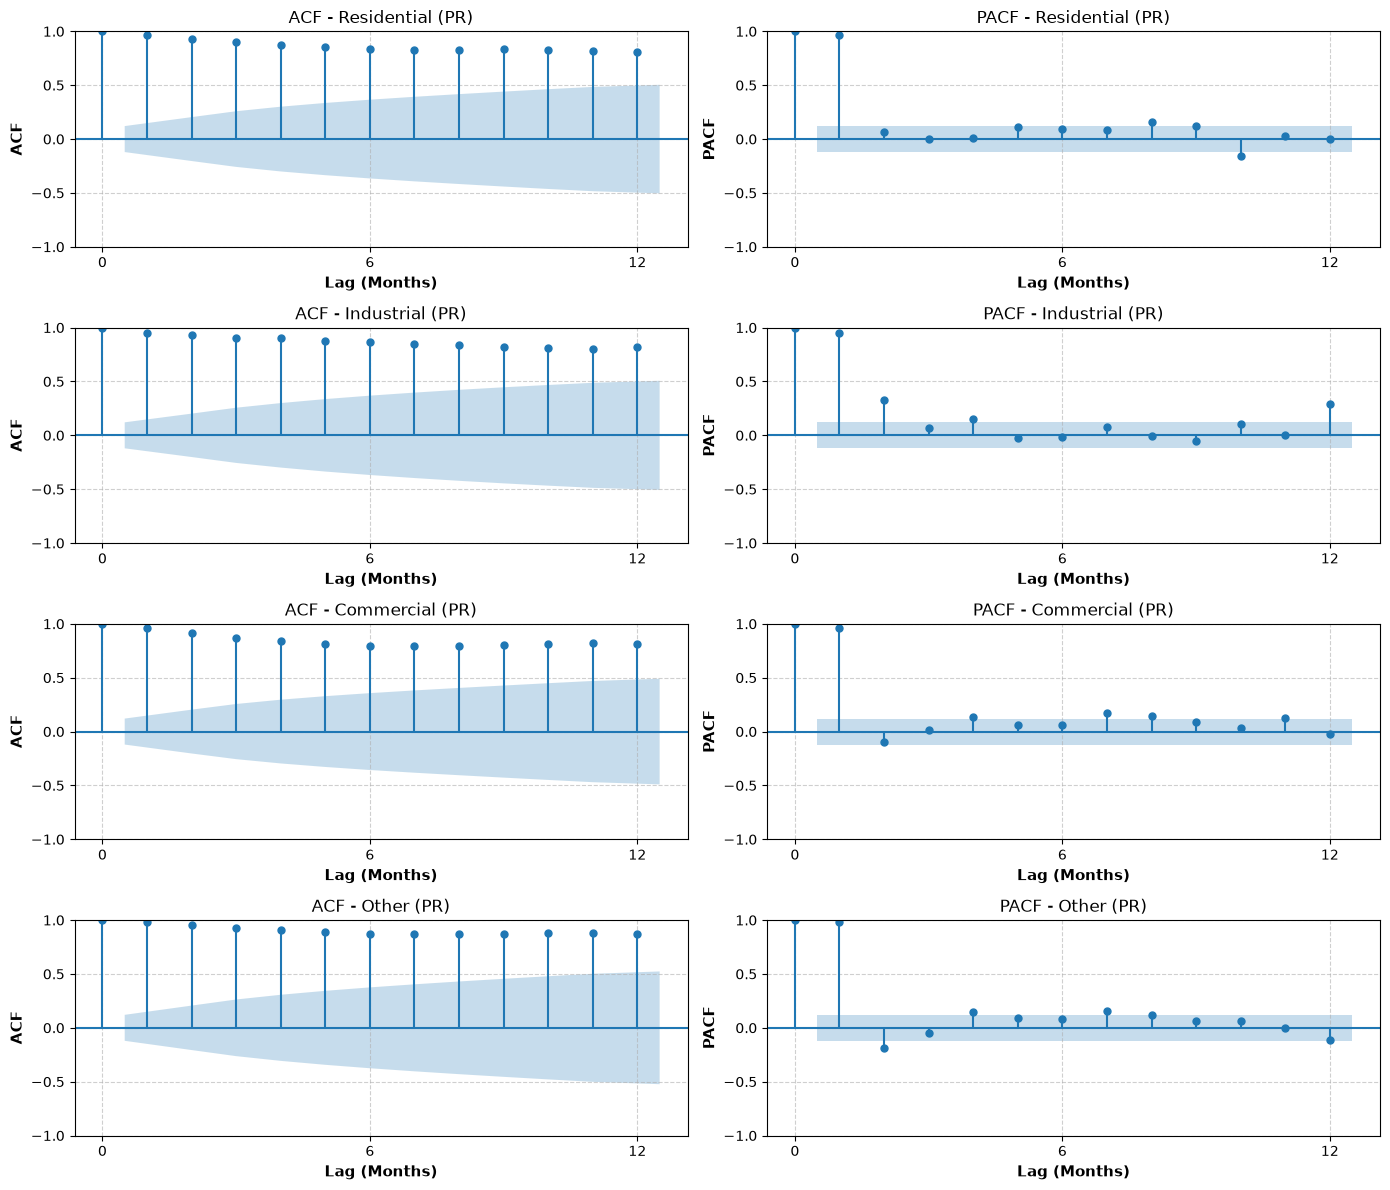

/tmp/ipykernel_67483/3840732150.py:32: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_stat, kpss_p = kpss(serie, regression="c", nlags="auto", result_object=True)
/tmp/ipykernel_67483/3840732150.py:32: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_stat, kpss_p = kpss(serie, regression="c", nlags="auto", result_object=True)
/tmp/ipykernel_67483/3840732150.py:32: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_stat, kpss_p = kpss(serie, regression="c", nlags="auto", result_object=True)
/tmp/ipykernel_67483/3840732150.py:32: InterpolationWarning: The test statistic is outside of the range of p-values available in the 

KPSS Stat KPSS p-value KPSS Conclusion (alpha=0.05)  \
State Consumption                                                        
PR    Residential     2.3346      <= 0.01               Non-Stationary   
      Industrial      2.3947      <= 0.01               Non-Stationary   
      Commercial      2.3105      <= 0.01               Non-Stationary   
      Other           2.4623      <= 0.01               Non-Stationary   

                   MK Tau  MK Sen Slope MK p-value MK Conclusion (alpha=0.05)  \
State Consumption                                                               
PR    Residential  0.8652       1633.46   0.00e+00               Upward Trend   
      Industrial   0.8383       2012.98   0.00e+00               Upward Trend   
      Commercial   0.7799       1394.94   0.00e+00               Upward Trend   
      Other        0.8487       1209.37   0.00e+00               Upward Trend   

                   KW Stat KW p-value KW Conclusion (alpha=0.05)  
State Consumption                                                 
PR    Residential   4.0885     0.9673               Non-Seasonal  
      Industrial    6.5703     0.8327               Non-Seasonal  
      Commercial   15.2222     0.1725               Non-Seasonal  
      Other         7.6852     0.7412               Non-Seasonal

In [7]:
plot_acf_pacf(df_pr, state_name="PR", lags=12)
df_tests_pr = run_hypothesis_tests(df_pr, state_name="PR")
display(df_tests_pr)


## Santa Catarina

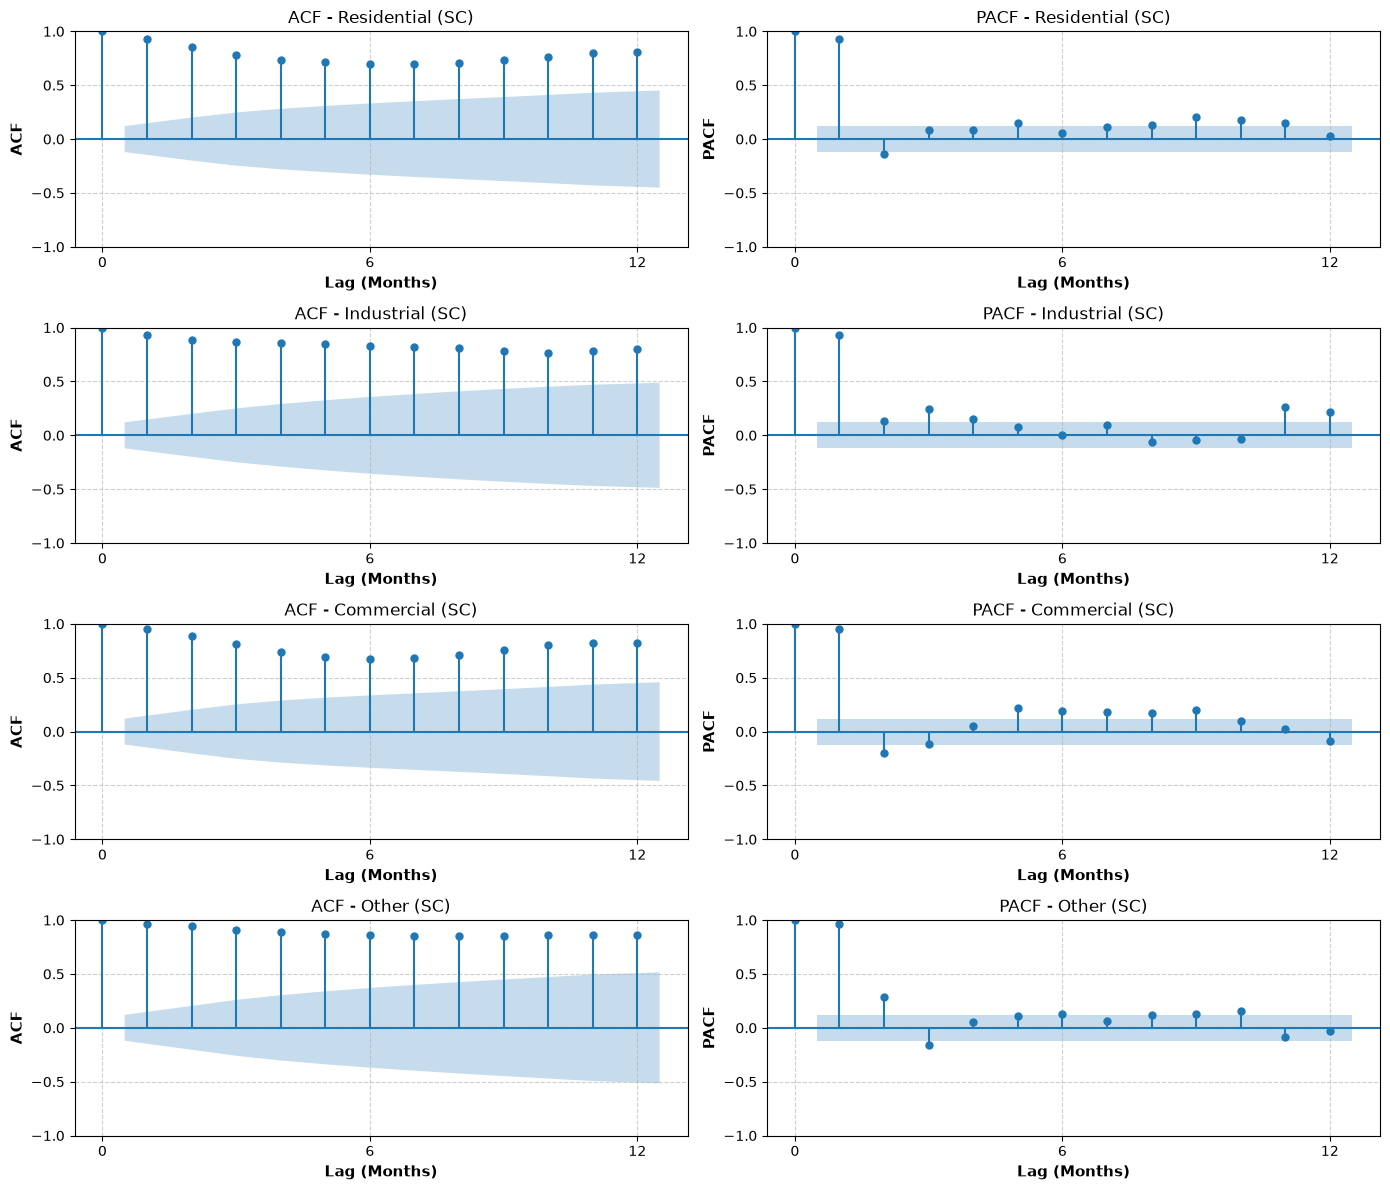

/tmp/ipykernel_67483/3840732150.py:32: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_stat, kpss_p = kpss(serie, regression="c", nlags="auto", result_object=True)
/tmp/ipykernel_67483/3840732150.py:32: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_stat, kpss_p = kpss(serie, regression="c", nlags="auto", result_object=True)
/tmp/ipykernel_67483/3840732150.py:32: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_stat, kpss_p = kpss(serie, regression="c", nlags="auto", result_object=True)
/tmp/ipykernel_67483/3840732150.py:32: InterpolationWarning: The test statistic is outside of the range of p-values available in the 

KPSS Stat KPSS p-value KPSS Conclusion (alpha=0.05)  \
State Consumption                                                        
SC    Residential     2.3730      <= 0.01               Non-Stationary   
      Industrial      2.3709      <= 0.01               Non-Stationary   
      Commercial      2.3658      <= 0.01               Non-Stationary   
      Other           2.2955      <= 0.01               Non-Stationary   

                   MK Tau  MK Sen Slope MK p-value MK Conclusion (alpha=0.05)  \
State Consumption                                                               
SC    Residential  0.8015       1403.86   0.00e+00               Upward Trend   
      Industrial   0.8044       1748.08   0.00e+00               Upward Trend   
      Commercial   0.7648       1137.24   0.00e+00               Upward Trend   
      Other        0.7077       1116.77   0.00e+00               Upward Trend   

                   KW Stat KW p-value KW Conclusion (alpha=0.05)  
State Consumption                                                 
SC    Residential  14.7692     0.1933               Non-Seasonal  
      Industrial   11.5111     0.4015               Non-Seasonal  
      Commercial   22.2717     0.0224                   Seasonal  
      Other        13.7156     0.2491               Non-Seasonal

In [8]:
plot_acf_pacf(df_sc, state_name="SC", lags=12)
df_tests_sc = run_hypothesis_tests(df_sc, state_name="SC")
display(df_tests_sc)


## Rio Grande do Sul

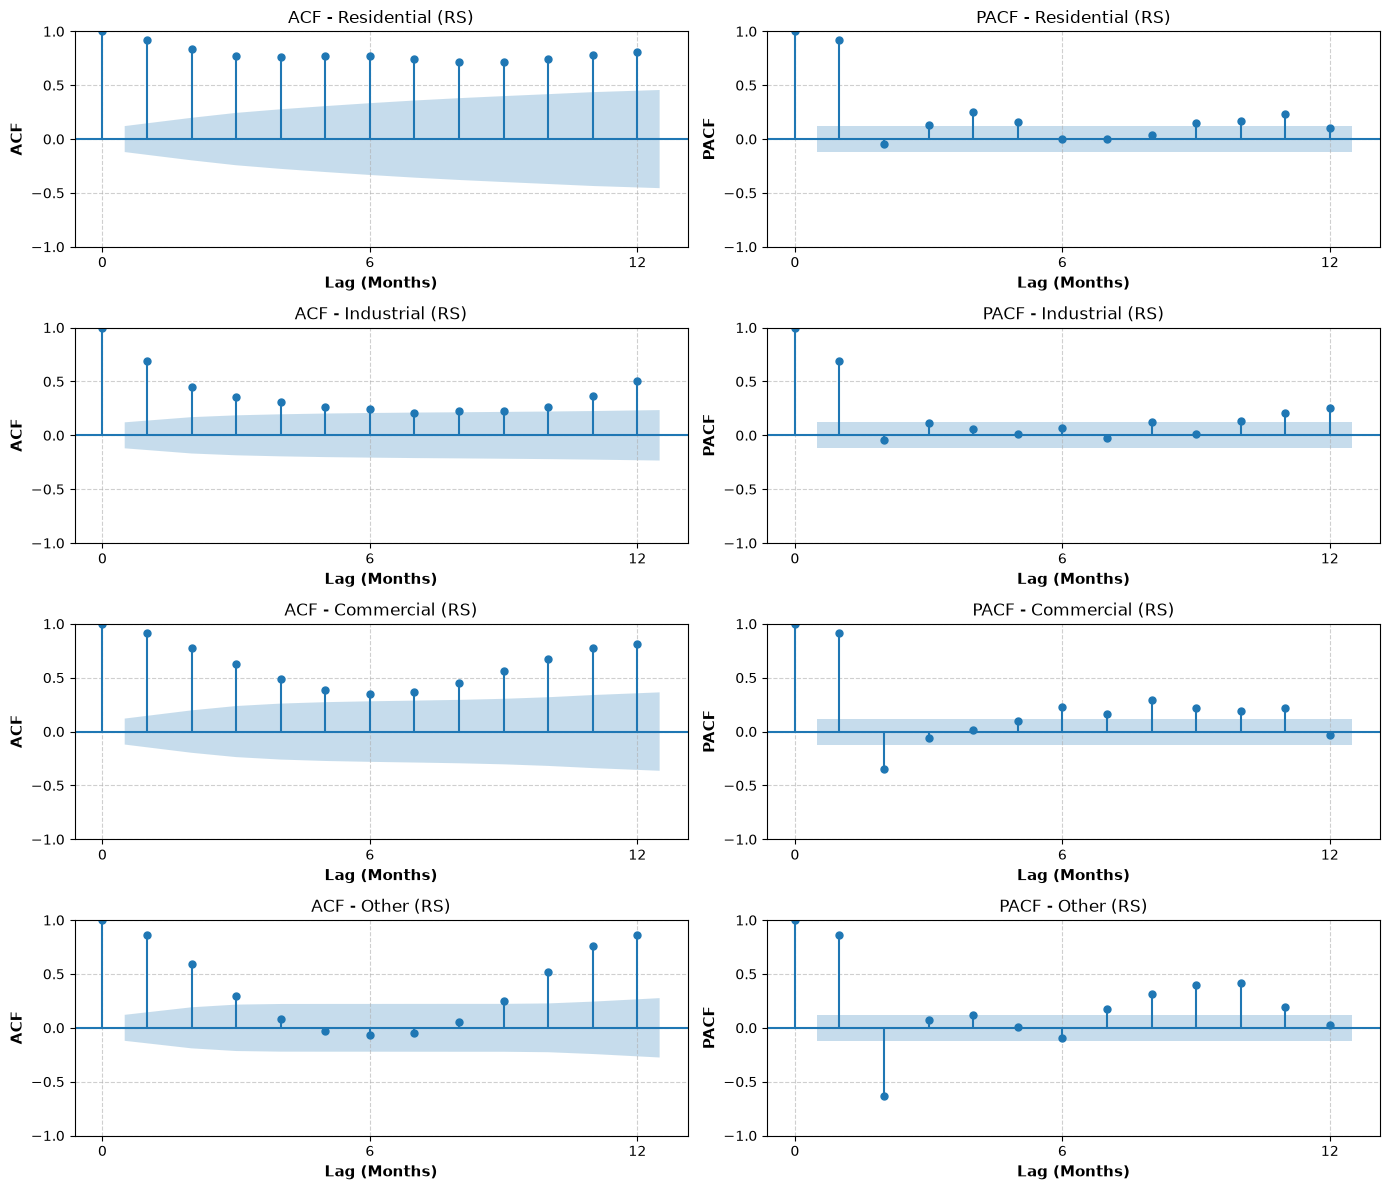

/tmp/ipykernel_67483/3840732150.py:32: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_stat, kpss_p = kpss(serie, regression="c", nlags="auto", result_object=True)
/tmp/ipykernel_67483/3840732150.py:32: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_stat, kpss_p = kpss(serie, regression="c", nlags="auto", result_object=True)
/tmp/ipykernel_67483/3840732150.py:32: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_stat, kpss_p = kpss(serie, regression="c", nlags="auto", result_object=True)
/tmp/ipykernel_67483/3840732150.py:32: InterpolationWarning: The test statistic is outside of the range of p-values available in the 

KPSS Stat KPSS p-value KPSS Conclusion (alpha=0.05)  \
State Consumption                                                        
RS    Residential     2.3755      <= 0.01               Non-Stationary   
      Industrial      1.0205      <= 0.01               Non-Stationary   
      Commercial      1.9227      <= 0.01               Non-Stationary   
      Other           1.7051      <= 0.01               Non-Stationary   

                   MK Tau  MK Sen Slope MK p-value MK Conclusion (alpha=0.05)  \
State Consumption                                                               
RS    Residential  0.7869       1742.98   0.00e+00               Upward Trend   
      Industrial   0.2493        312.35   1.60e-09               Upward Trend   
      Commercial   0.5041        681.18   0.00e+00               Upward Trend   
      Other        0.3147        651.13   2.58e-14               Upward Trend   

                    KW Stat KW p-value KW Conclusion (alpha=0.05)  
State Consumption                                                  
RS    Residential   15.0568     0.1799               Non-Seasonal  
      Industrial    71.1380   7.42e-11                   Seasonal  
      Commercial    64.4773   1.35e-09                   Seasonal  
      Other        138.5033   3.28e-24                   Seasonal

In [9]:
plot_acf_pacf(df_rs, state_name="RS", lags=12)
df_tests_rs = run_hypothesis_tests(df_rs, state_name="RS")
display(df_tests_rs)


## Compiled Hypothesis Tests

In [10]:
df_tests_all = pd.concat([df_tests_pr, df_tests_sc, df_tests_rs])
df_tests_all.to_csv("../paper/materials/hypothesis_tests_all.csv")
df_tests_all

KPSS Stat KPSS p-value KPSS Conclusion (alpha=0.05)  \
State Consumption                                                        
PR    Residential     2.3346      <= 0.01               Non-Stationary   
      Industrial      2.3947      <= 0.01               Non-Stationary   
      Commercial      2.3105      <= 0.01               Non-Stationary   
      Other           2.4623      <= 0.01               Non-Stationary   
SC    Residential     2.3730      <= 0.01               Non-Stationary   
      Industrial      2.3709      <= 0.01               Non-Stationary   
      Commercial      2.3658      <= 0.01               Non-Stationary   
      Other           2.2955      <= 0.01               Non-Stationary   
RS    Residential     2.3755      <= 0.01               Non-Stationary   
      Industrial      1.0205      <= 0.01               Non-Stationary   
      Commercial      1.9227      <= 0.01               Non-Stationary   
      Other           1.7051      <= 0.01               Non-Stationary   

                   MK Tau  MK Sen Slope MK p-value MK Conclusion (alpha=0.05)  \
State Consumption                                                               
PR    Residential  0.8652       1633.46   0.00e+00               Upward Trend   
      Industrial   0.8383       2012.98   0.00e+00               Upward Trend   
      Commercial   0.7799       1394.94   0.00e+00               Upward Trend   
      Other        0.8487       1209.37   0.00e+00               Upward Trend   
SC    Residential  0.8015       1403.86   0.00e+00               Upward Trend   
      Industrial   0.8044       1748.08   0.00e+00               Upward Trend   
      Commercial   0.7648       1137.24   0.00e+00               Upward Trend   
      Other        0.7077       1116.77   0.00e+00               Upward Trend   
RS    Residential  0.7869       1742.98   0.00e+00               Upward Trend   
      Industrial   0.2493        312.35   1.60e-09               Upward Trend   
      Commercial   0.5041        681.18   0.00e+00               Upward Trend   
      Other        0.3147        651.13   2.58e-14               Upward Trend   

                    KW Stat KW p-value KW Conclusion (alpha=0.05)  
State Consumption                                                  
PR    Residential    4.0885     0.9673               Non-Seasonal  
      Industrial     6.5703     0.8327               Non-Seasonal  
      Commercial    15.2222     0.1725               Non-Seasonal  
      Other          7.6852     0.7412               Non-Seasonal  
SC    Residential   14.7692     0.1933               Non-Seasonal  
      Industrial    11.5111     0.4015               Non-Seasonal  
      Commercial    22.2717     0.0224                   Seasonal  
      Other         13.7156     0.2491               Non-Seasonal  
RS    Residential   15.0568     0.1799               Non-Seasonal  
      Industrial    71.1380   7.42e-11                   Seasonal  
      Commercial    64.4773   1.35e-09                   Seasonal  
      Other        138.5033   3.28e-24                   Seasonal

# Boxplots

In [11]:
def plot_boxplpot(dataframe, filename):
    var_groups = {
        "Electricity Consumption (MWh)": targets,
        "Consumers (Count)": consumers,
        "2m Temperature": sorted([c for c in dataframe.columns if "2 metre temperature_" in c]),
        "2m Dewpoint Temperature": sorted([c for c in dataframe.columns if "2 metre dewpoint temperature_" in c]),
        "10m U Wind": sorted([c for c in dataframe.columns if "10 metre U wind component_" in c]),
        "10m V Wind": sorted([c for c in dataframe.columns if "10 metre V wind component_" in c]),
        "Mean Sea Level Pressure": sorted([c for c in dataframe.columns if "Mean sea level pressure_" in c]),
        "Surface Pressure": sorted([c for c in dataframe.columns if "Surface pressure_" in c]),
        "Total Precipitation": sorted([c for c in dataframe.columns if "Total precipitation_" in c]),
        "Total Cloud Cover": sorted([c for c in dataframe.columns if "Total cloud cover_" in c]),
    }

    palette = sns.color_palette("tab10", len(var_groups))

    fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(28, 12))
    axes = axes.flatten()

    for i, ((title, cols), color) in enumerate(zip(var_groups.items(), palette)):
        ax = axes[i]

        simplified_labels = [
            f"{c.split('_')[-2]}_{c.split('_')[-1]}" if any(q in c for q in ["Q1", "Q2", "Q3", "Q4"])
            else c.replace(" Consumers", "")
            for c in cols
        ]

        data = [dataframe[c].dropna().values for c in cols]

        bp = ax.boxplot(
            data,
            tick_labels=simplified_labels,
            patch_artist=True,
            medianprops=dict(color="black", linewidth=1.5),
            flierprops=dict(marker="o", markersize=3, alpha=0.4, markerfacecolor=color)
        )
        for patch in bp["boxes"]:
            patch.set_facecolor(color)
            patch.set_alpha(0.65)

        ax.set_title(title, fontsize=12, fontweight="bold", pad=8)
        ax.grid(True, linestyle="--", alpha=0.5, axis="y")
        ax.tick_params(axis="y", labelsize=9)
        ax.tick_params(axis="x", labelsize=9, rotation=90)
        ax.ticklabel_format(style="plain", axis="y", useOffset=False)

    plt.tight_layout()
    plt.savefig(f"../paper/materials/{filename}.png", dpi=300, bbox_inches="tight")
    plt.show()

## Without Data Clean


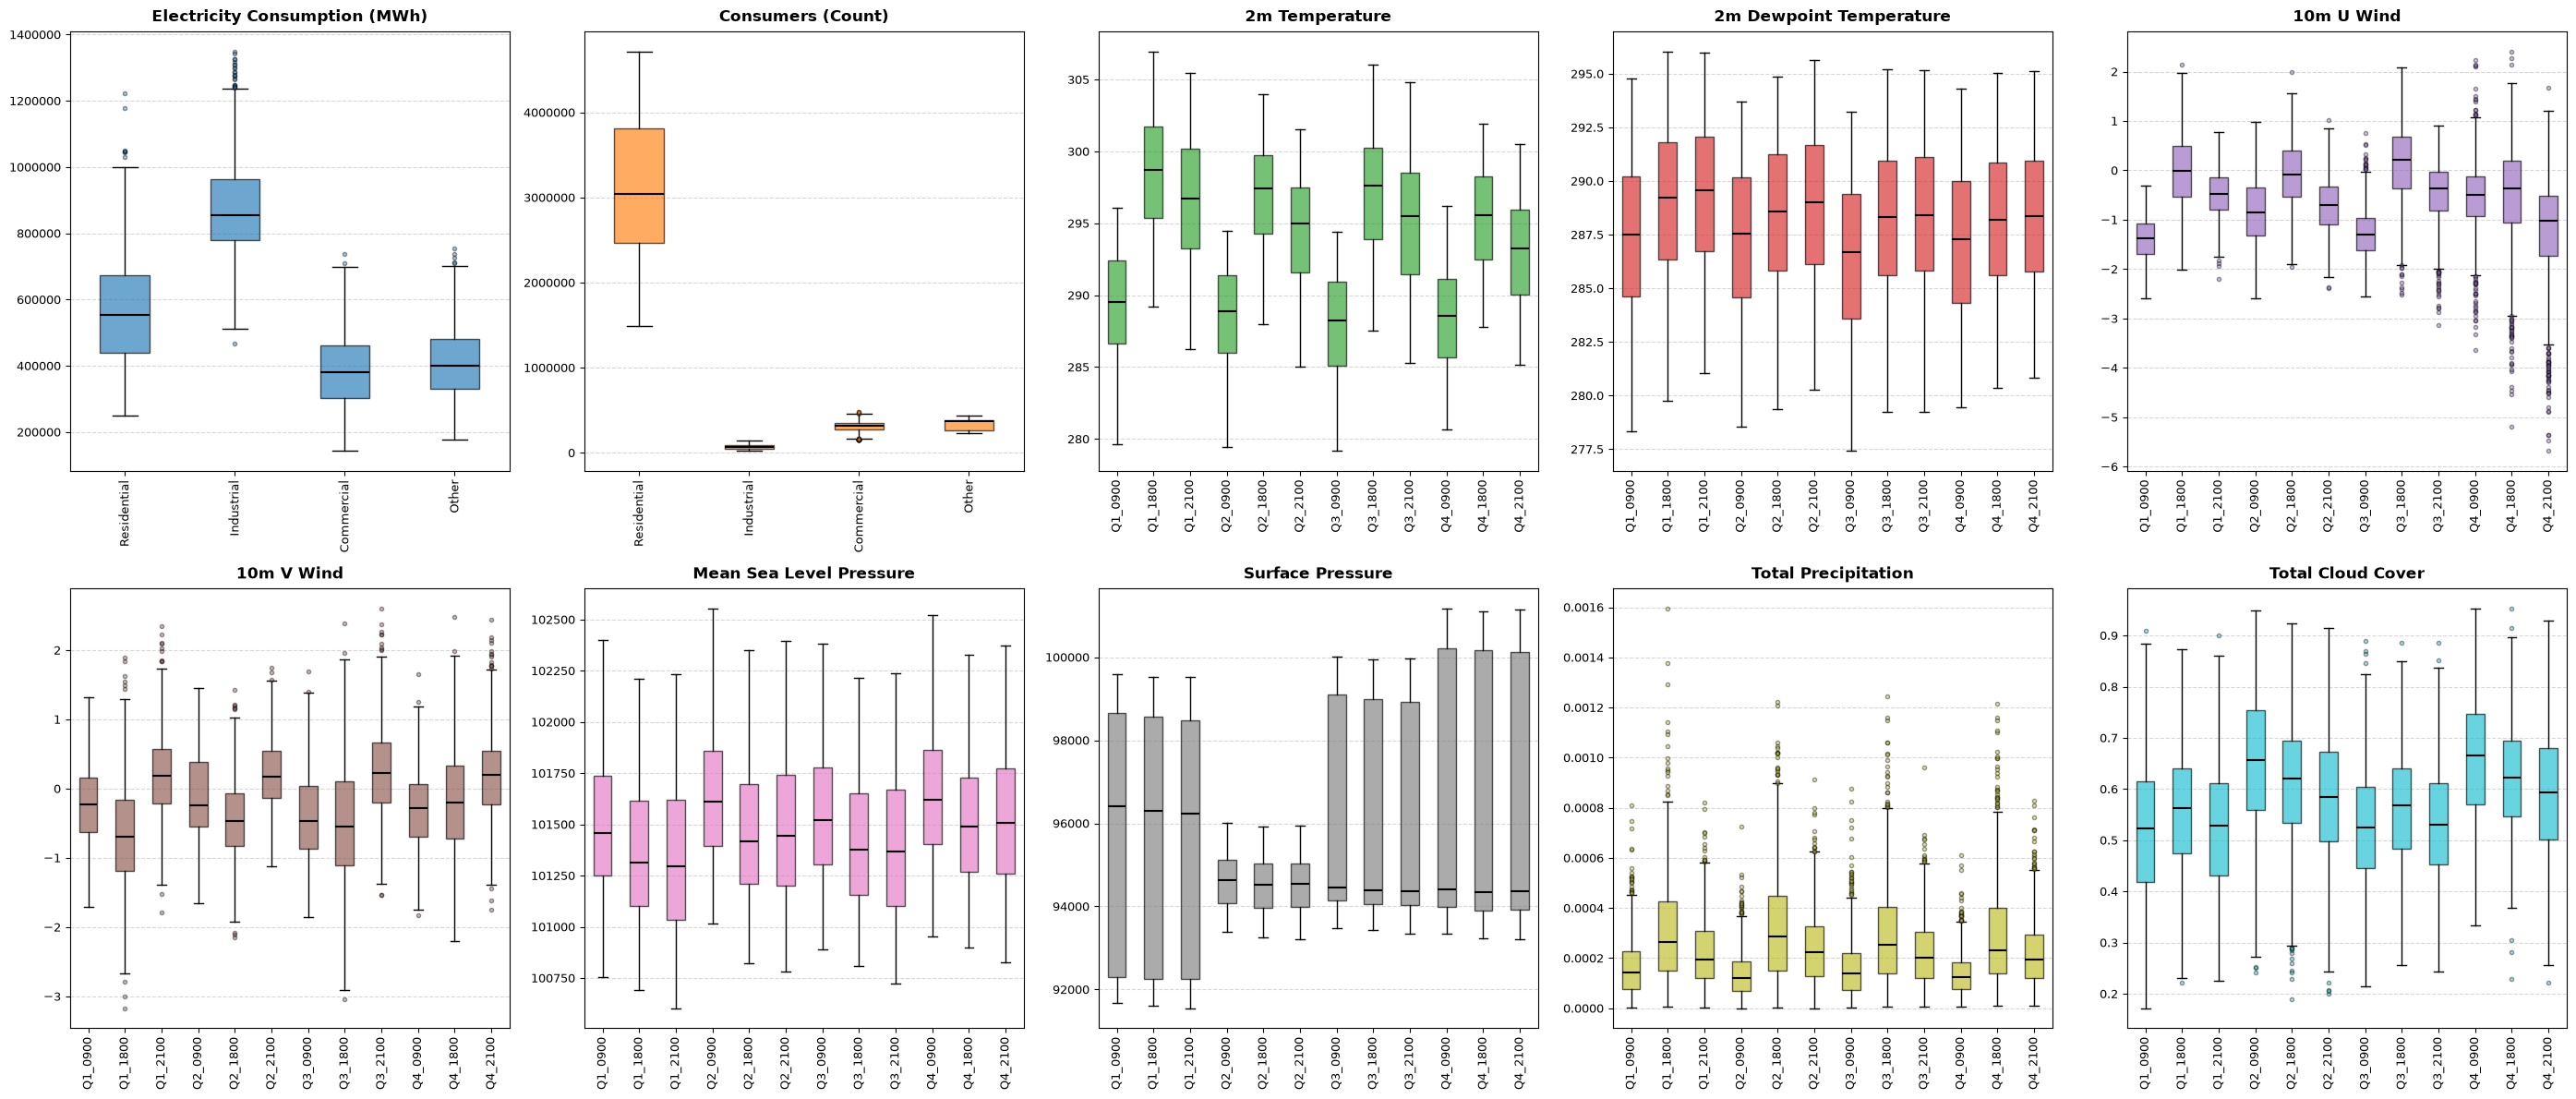

In [12]:
plot_boxplpot(df_consumption, "boxplot_original_data")

## With Data Clean

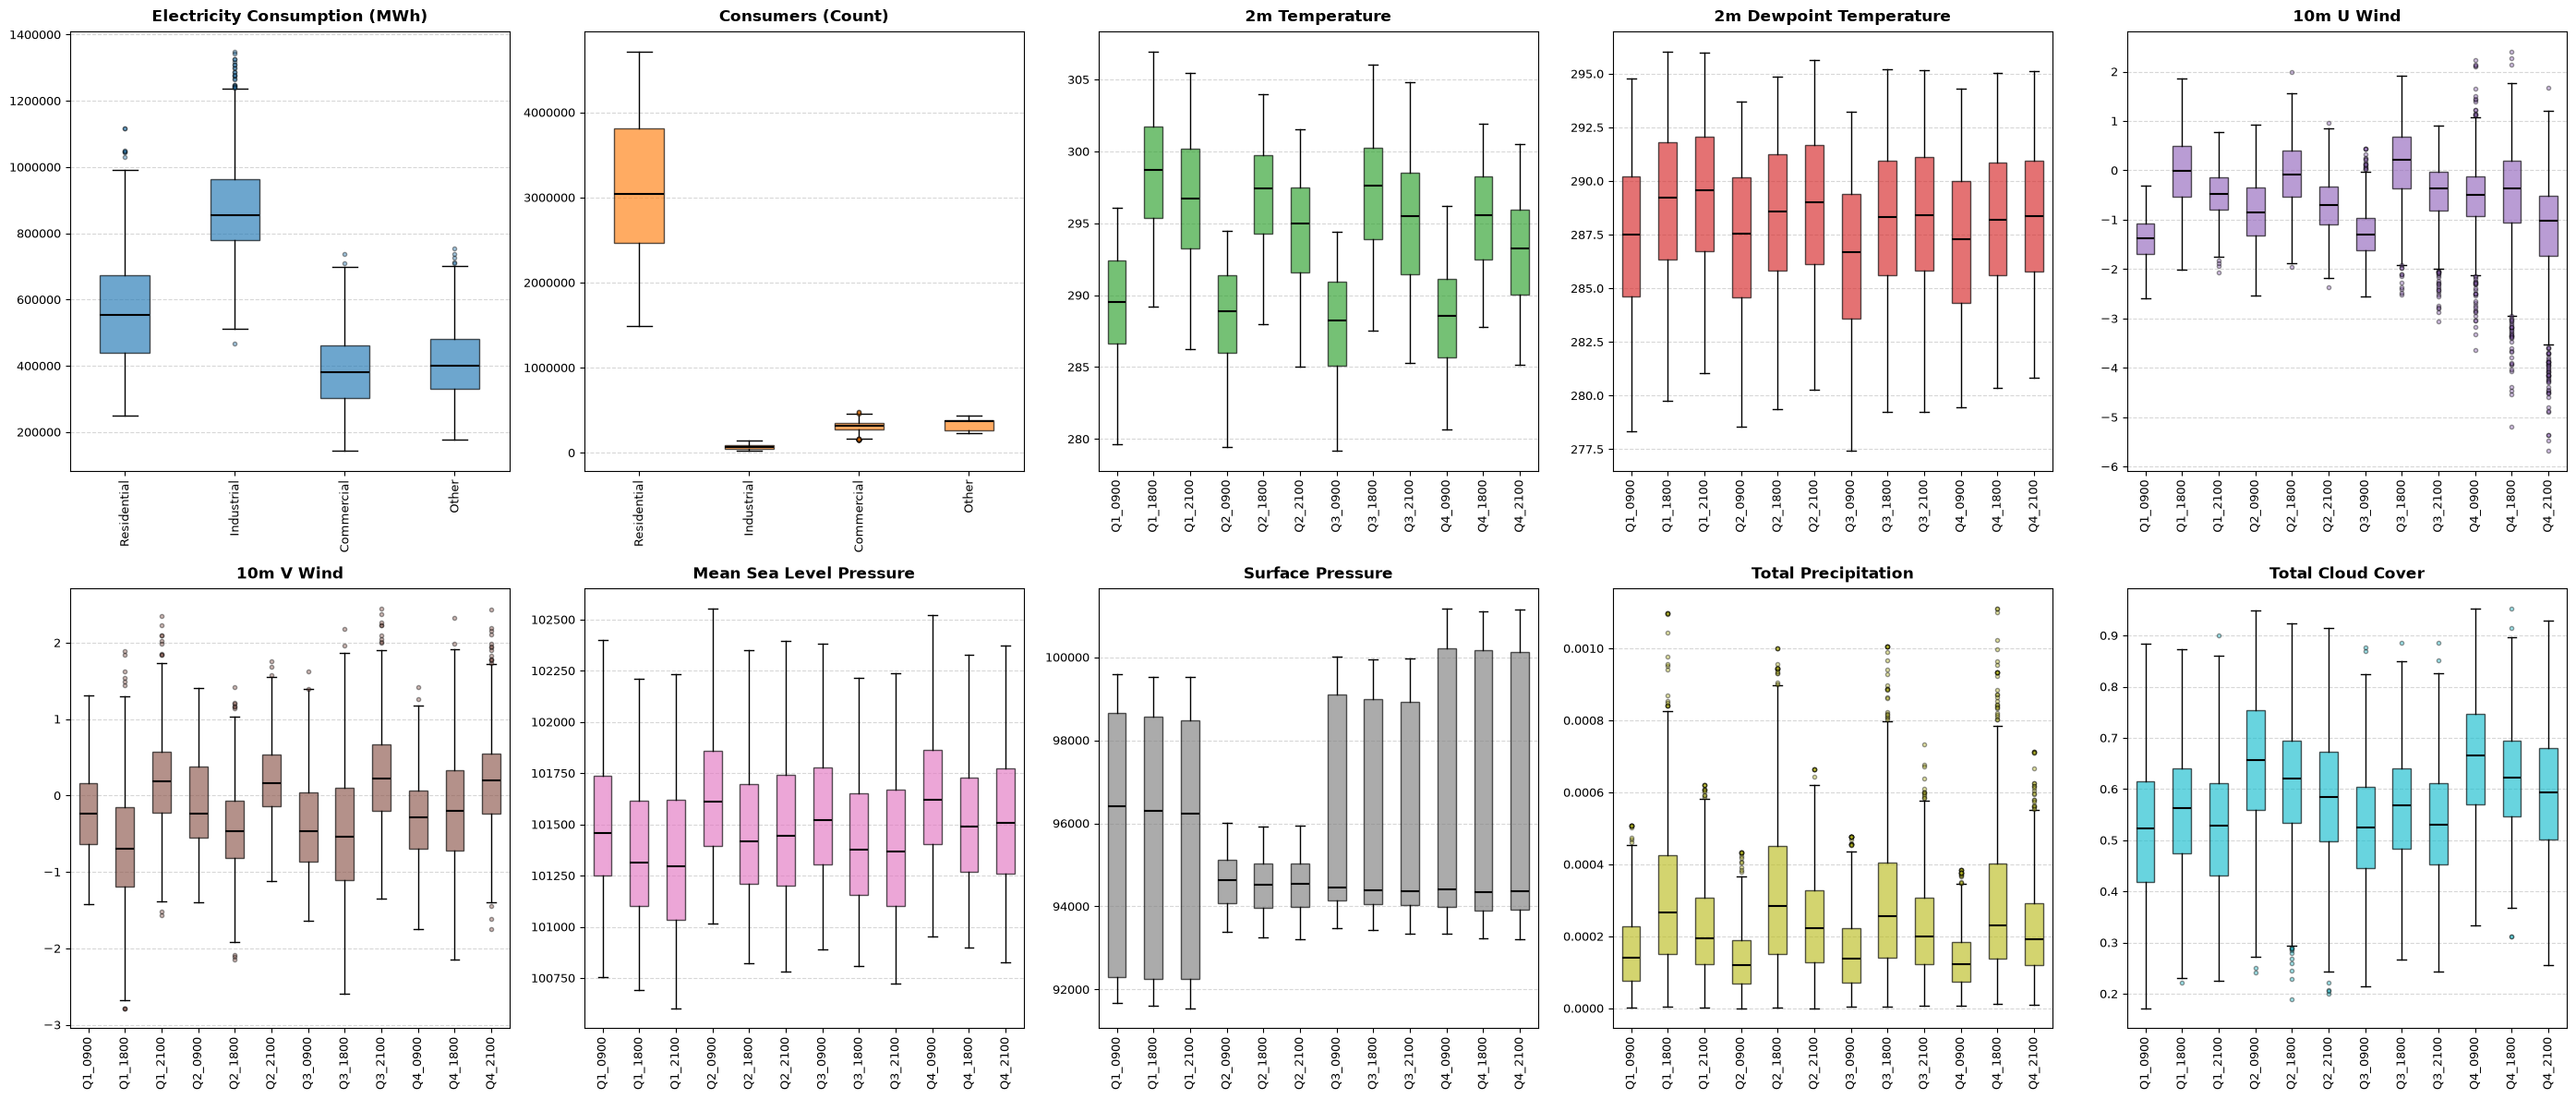

In [13]:
plot_boxplpot(df_consumption_cleaned, "boxplot_cleaned_data")

# Correlation Analysis

In [14]:
def plot_heatmap_correlation(
    dataframe,
    title="Correlation Matrix",
    figsize=(12, 8),
    fmt=".2f",
):
    numeric_cols = dataframe.select_dtypes(include="number").columns.tolist()

    if targets is not None:
        ordered_targets = [c for c in targets if c in numeric_cols]
        other_cols = [c for c in numeric_cols if c not in ordered_targets]
        ordered_cols = ordered_targets + other_cols
    else:
        ordered_cols = numeric_cols

    corr_matrix = dataframe[ordered_cols].dropna().corr()

    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(
        corr_matrix,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        annot=True,
        fmt=fmt,
        linewidths=0.5,
        cbar_kws={"shrink": 0.8},
        ax=ax,
    )

    ax.set_title(title, fontsize=14, fontweight="bold", pad=12)
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

## Consumption vs Consumers

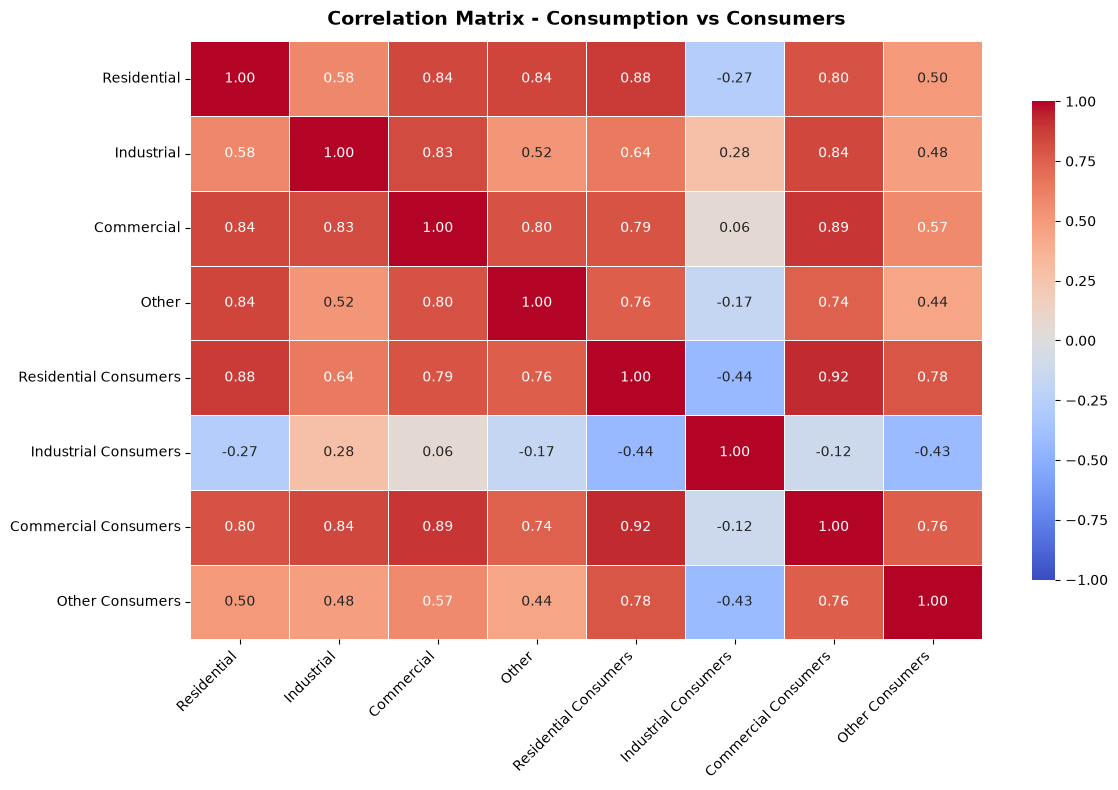

In [15]:
plot_heatmap_correlation(df_consumption_cleaned[targets + consumers], "Correlation Matrix - Consumption vs Consumers")

## Consumption vs Lags

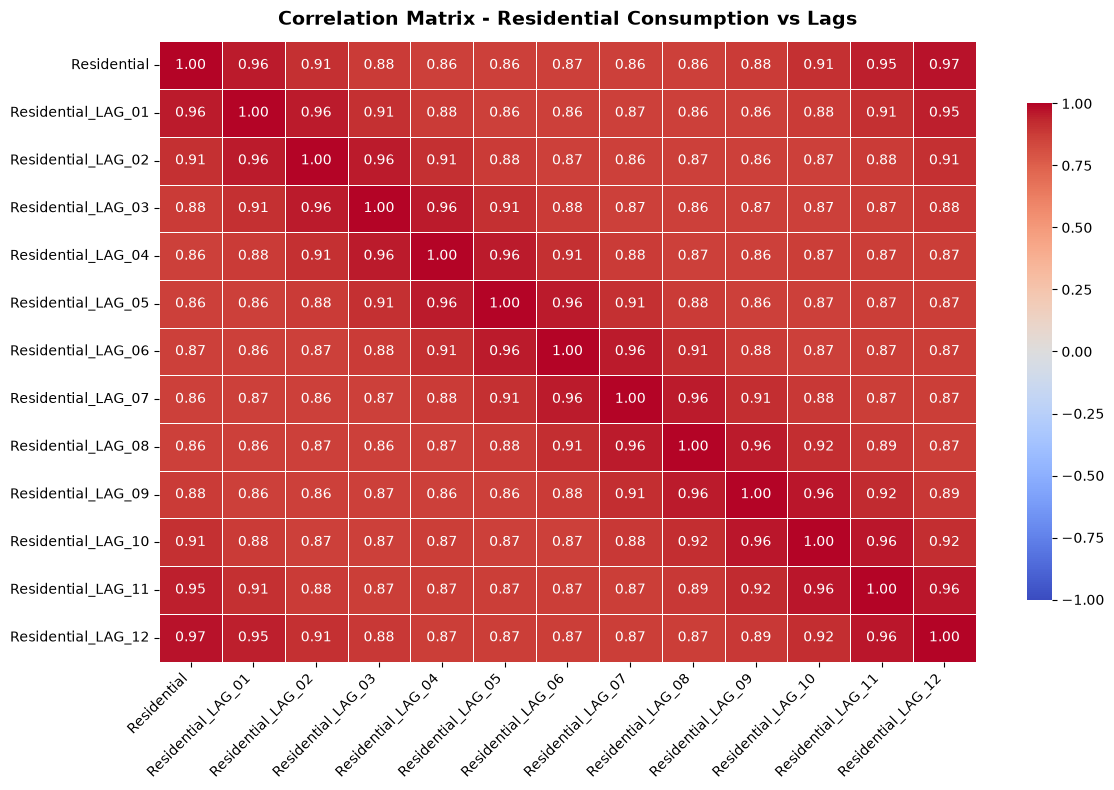

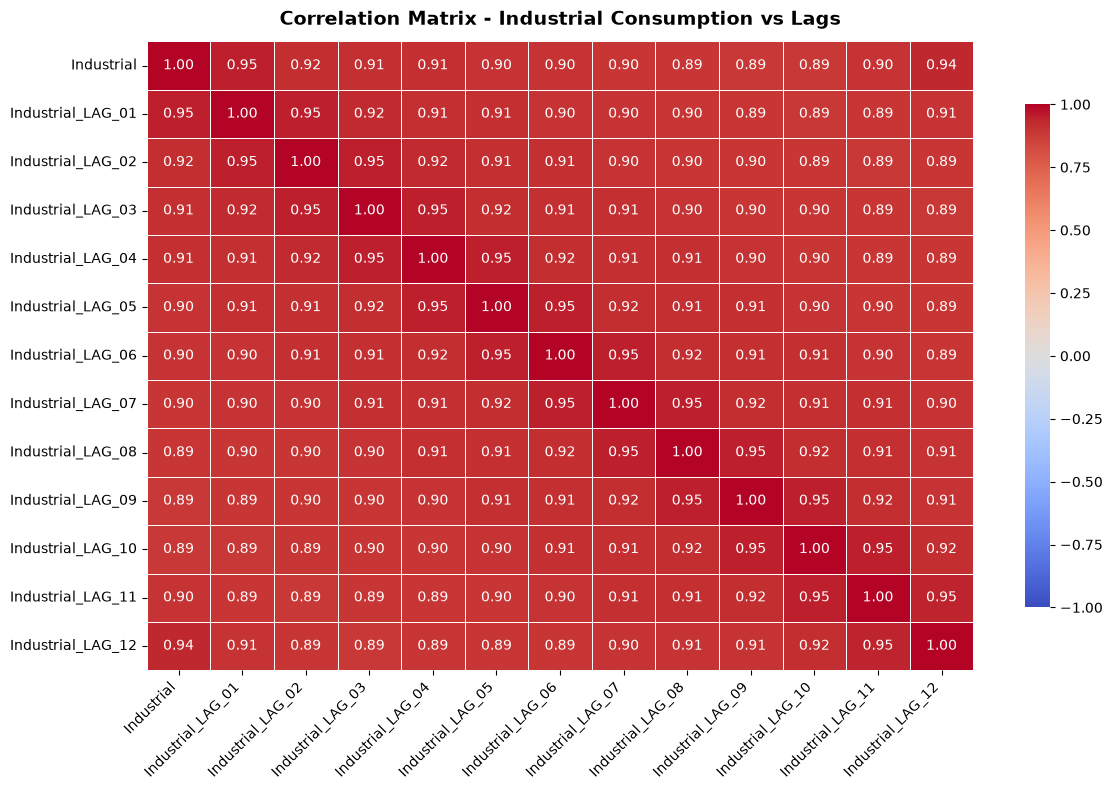

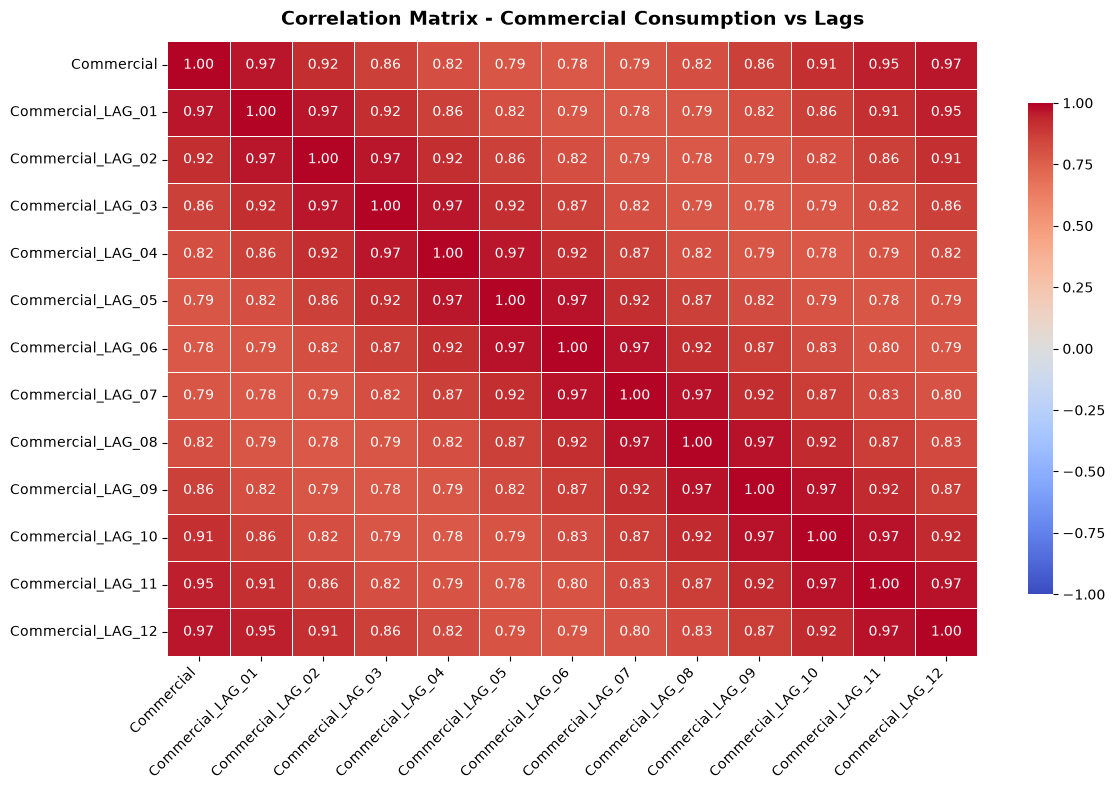

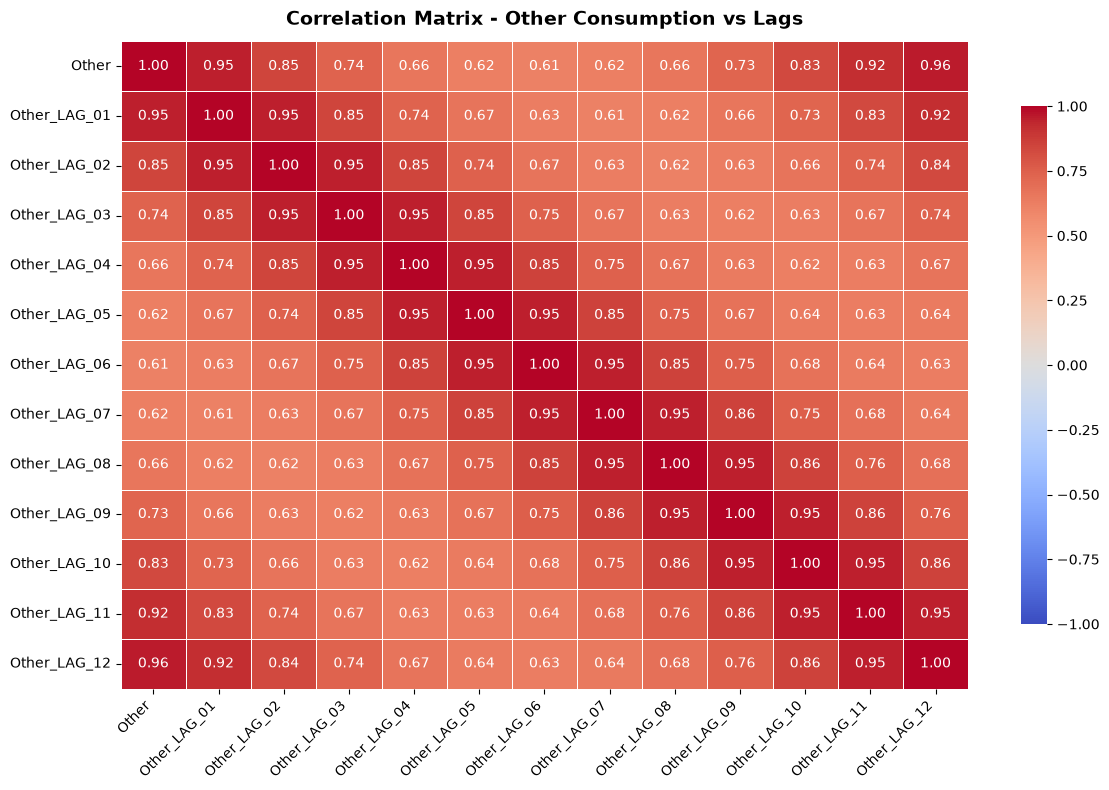

In [16]:
for target in targets:
    df_lags = create_lags(df_consumption, target, 12, groupby_col="State")
    lag_cols = [f"{target}_LAG_{i:02d}" for i in range(1, 13)]

    plot_heatmap_correlation(
        df_lags[[target] + lag_cols],
        title=f"Correlation Matrix - {target} Consumption vs Lags"
    )

## Consumption vs Climate Data

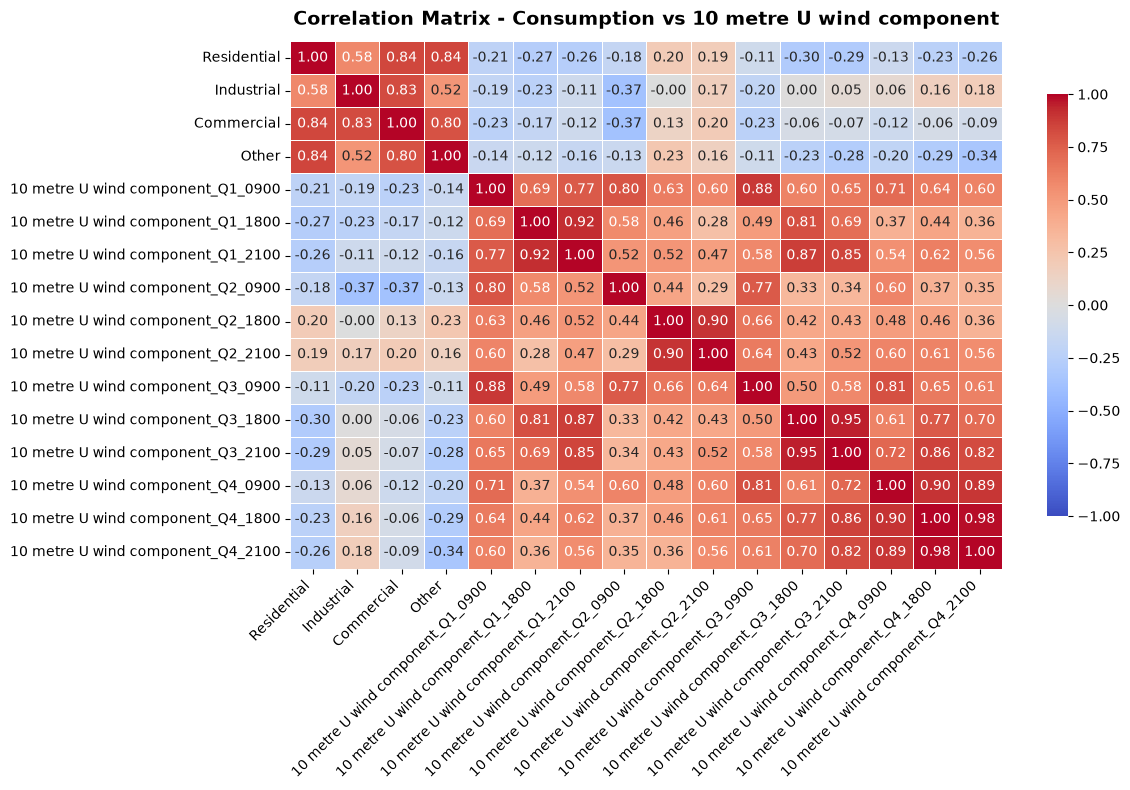

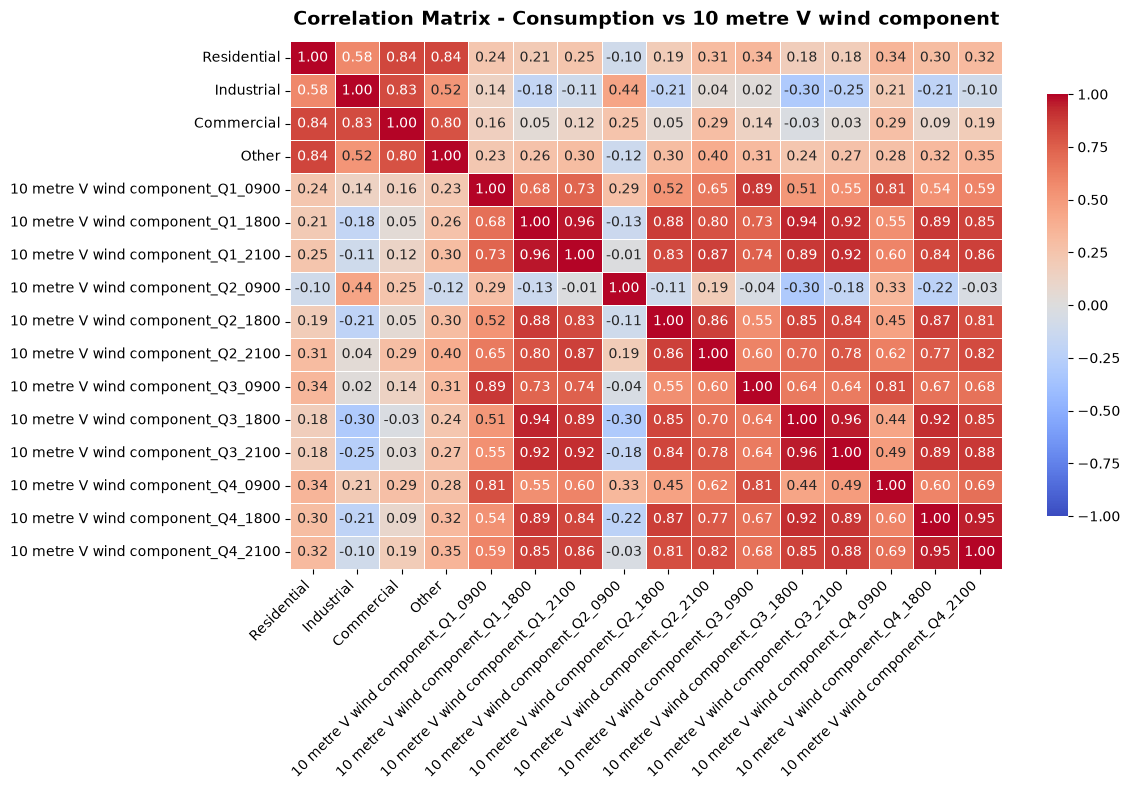

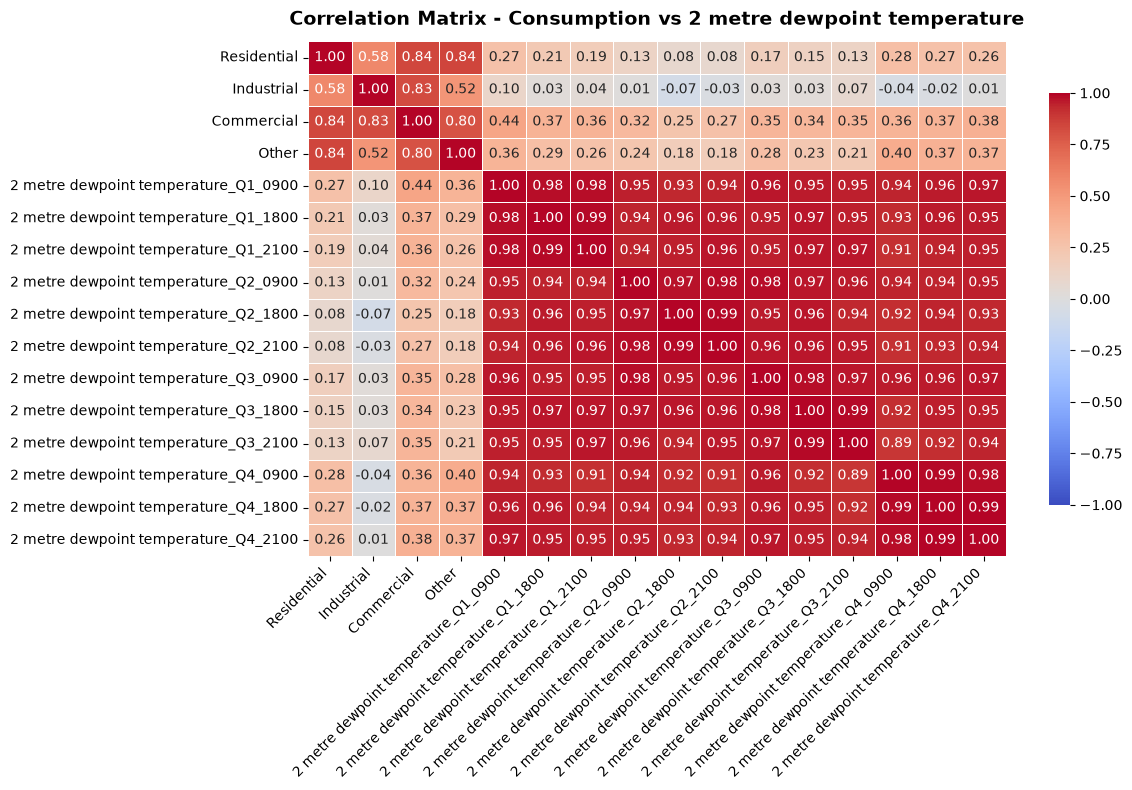

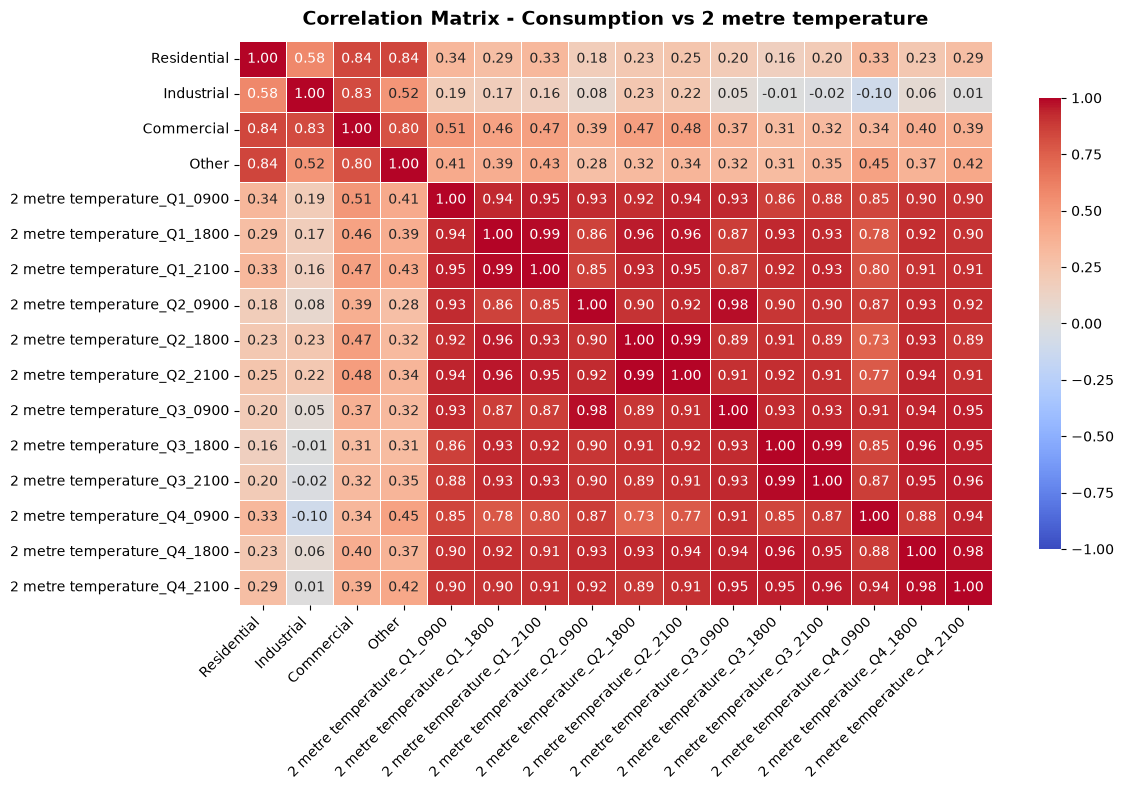

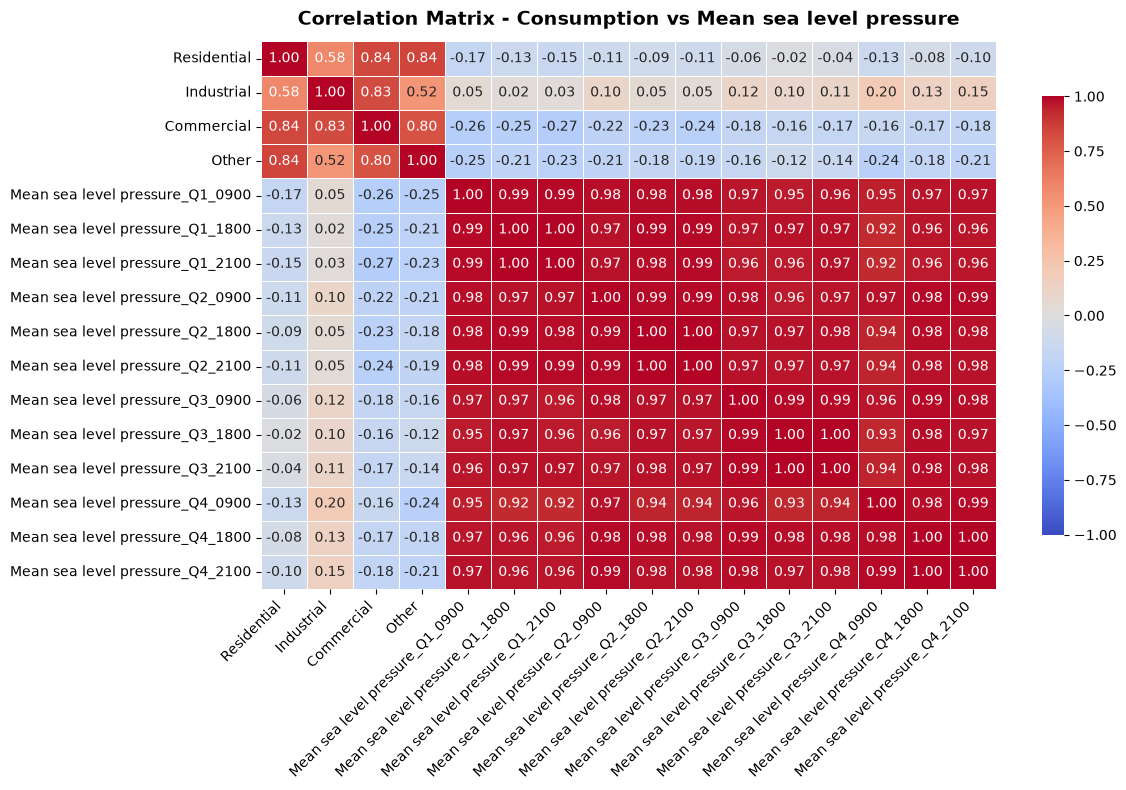

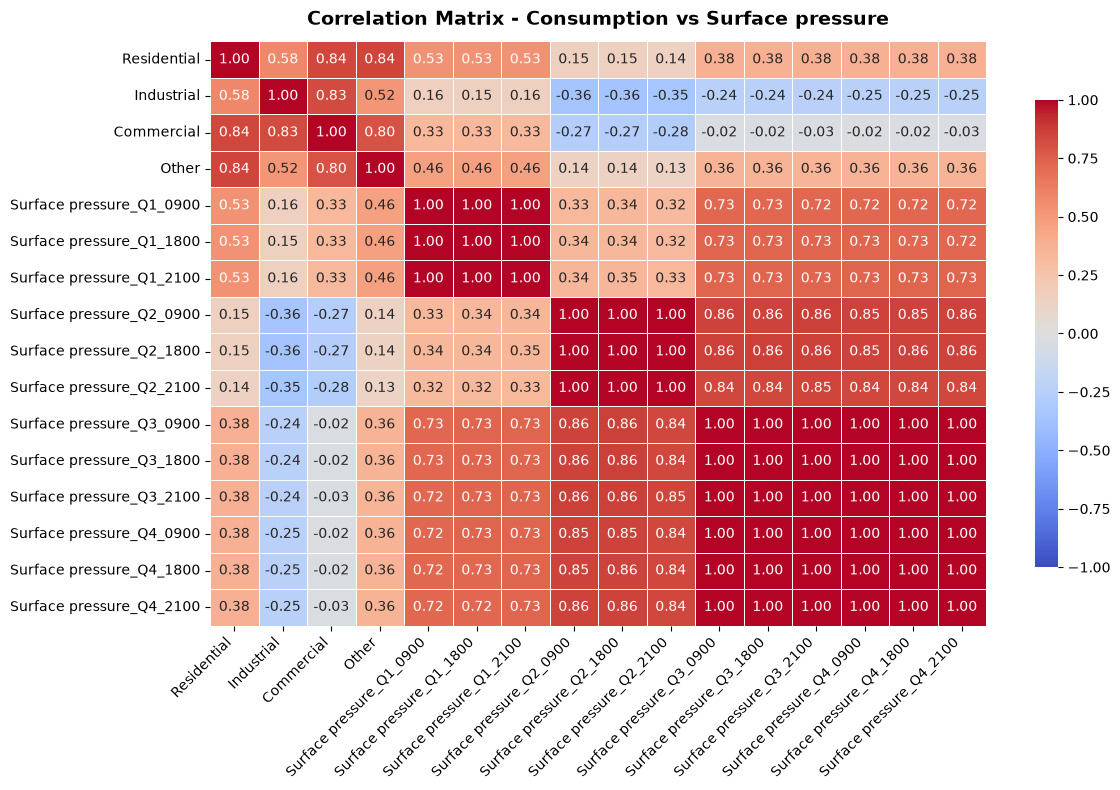

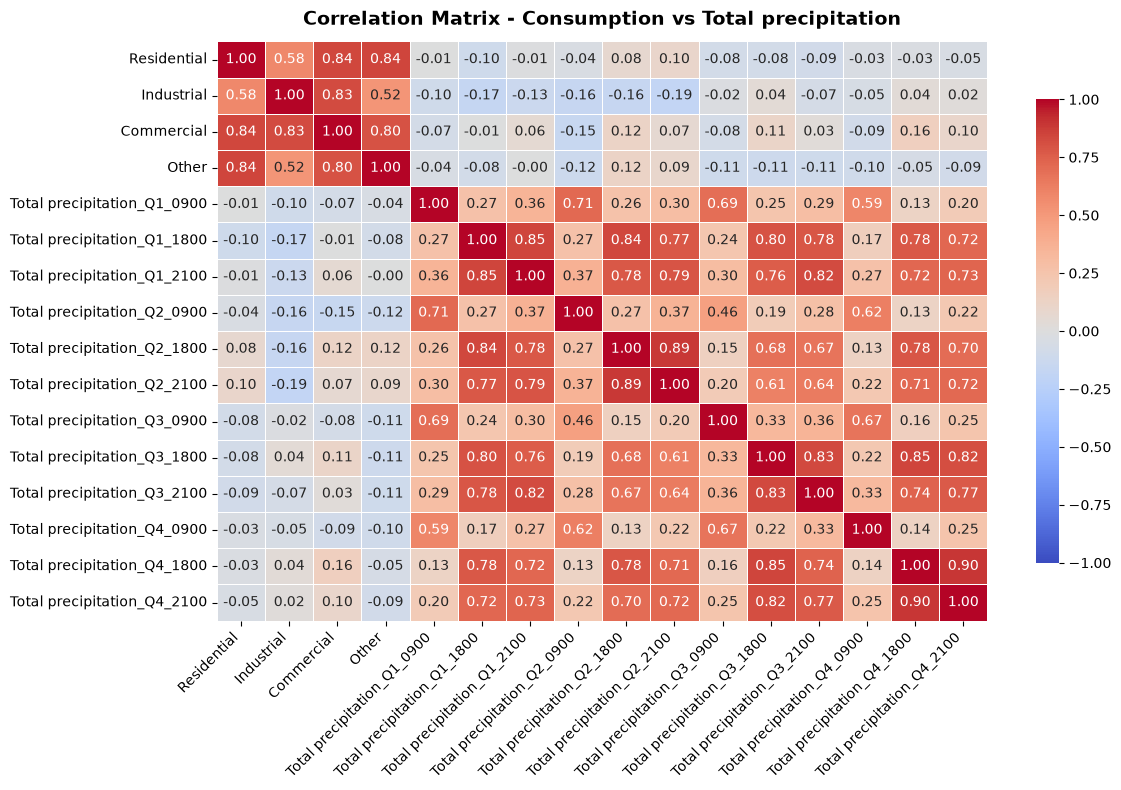

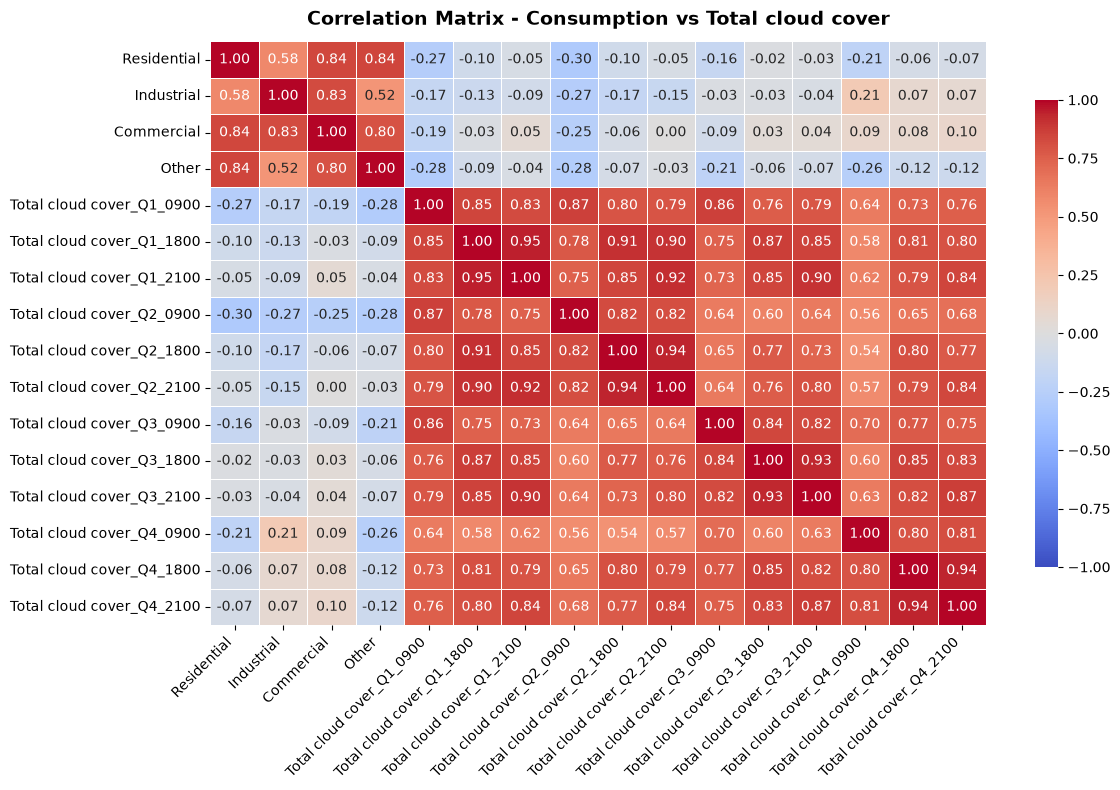

In [17]:
for var in CAMS_VARS + ERA5_VARS:
    var_cols = sorted([col for col in df_consumption_cleaned.columns if col.startswith(f"{var}_")])

    plot_heatmap_correlation(
        df_consumption_cleaned[targets + var_cols],
        title=f"Correlation Matrix - Consumption vs {var}"
    )

# Final Dataset

In [18]:
df_consumption_cleaned

,Date,State_PR,State_RS,State_SC,Month_1,Month_2,Month_3,Month_4,Month_5,Month_6,...,Commercial_LAG_10,Other_LAG_10,Residential_LAG_11,Industrial_LAG_11,Commercial_LAG_11,Other_LAG_11,Residential_LAG_12,Industrial_LAG_12,Commercial_LAG_12,Other_LAG_12
0,01/2004,1,0,0,1,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,02/2004,1,0,0,0,1,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,03/2004,1,0,0,0,0,1,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,04/2004,1,0,0,0,0,0,1,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,05/2004,1,0,0,0,0,0,0,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
787,08/2025,0,0,1,0,0,0,0,0,0,...,440638.0,373446.0,556095.0,1039640.0,404040.0,379302.0,600646.0,1065113.0,414661.0,511536.0
788,09/2025,0,0,1,0,0,0,0,0,0,...,482213.0,408686.0,585989.0,1114040.0,440638.0,373446.0,556095.0,1039640.0,404040.0,379302.0
789,10/2025,0,0,1,0,0,0,0,0,0,...,417321.0,459178.0,621667.0,1072557.0,482213.0,408686.0,585989.0,1114040.0,440638.0,373446.0
790,11/2025,0,0,1,0,0,0,0,0,0,...,584604.0,462765.0,634414.0,896725.0,417321.0,459178.0,621667.0,1072557.0,482213.0,408686.0
